In [1]:
# pandas pour manipuler les tableaux de données
import pandas as pd
# numpy pour le calcul numérique (log, infini, tableaux)
import numpy as np
# matplotlib pour les graphiques
import matplotlib.pyplot as plt
# seaborn, au-dessus de matplotlib, pour les graphiques statistiques
import seaborn as sns

# Montrer jusqu'à 60 colonnes à l'affichage au lieu de les cacher avec "..."
pd.set_option("display.max_columns", 60)
# Fond blanc avec grille pour tous les graphiques
sns.set_style("whitegrid")
# Graine fixe : on obtient les mêmes résultats à chaque exécution
RANDOM_STATE = 42

In [2]:
# Charger le fichier CSV dans un DataFrame
df = pd.read_csv("cumulative.csv")

# Nombre de lignes et de colonnes
print("Shape (rows, columns):", df.shape)
# Saut de ligne
print()
# Noms de toutes les colonnes
print(df.columns.tolist())

Shape (rows, columns): (9564, 50)

['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']


In [3]:
# Les 5 premières lignes, pour voir à quoi ressemblent les données
df.head()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,9.488036,2.775000e-05,-2.775000e-05,170.538750,0.002160,-0.002160,0.146,0.318,-0.146,2.95750,0.08190,-0.08190,615.8,19.5,-19.5,2.26,0.26,-0.15,793.0,NaN,NaN,93.59,29.45,-16.65,35.8,1.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,54.418383,2.479000e-04,-2.479000e-04,162.513840,0.003520,-0.003520,0.586,0.059,-0.443,4.50700,0.11600,-0.11600,874.8,35.5,-35.5,2.83,0.32,-0.19,443.0,NaN,NaN,9.11,2.87,-1.62,25.8,2.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,19.899140,1.494000e-05,-1.494000e-05,175.850252,0.000581,-0.000581,0.969,5.126,-0.077,1.78220,0.03410,-0.03410,10829.0,171.0,-171.0,14.60,3.92,-1.31,638.0,NaN,NaN,39.30,31.04,-10.49,76.3,1.0,q1_q17_dr25_tce,5853.0,158.0,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,1.736952,2.630000e-07,-2.630000e-07,170.307565,0.000115,-0.000115,1.276,0.115,-0.092,2.40641,0.00537,-0.00537,8079.2,12.8,-12.8,33.46,8.50,-2.83,1395.0,NaN,NaN,891.96,668.95,-230.35,505.6,1.0,q1_q17_dr25_tce,5805.0,157.0,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,2.525592,3.761000e-06,-3.761000e-06,171.595550,0.001130,-0.001130,0.701,0.235,-0.478,1.65450,0.04200,-0.04200,603.3,16.9,-16.9,2.75,0.88,-0.35,1406.0,NaN,NaN,926.16,874.33,-314.24,40.9,1.0,q1_q17_dr25_tce,6031.0,169.0,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [4]:
# Combien d'objets dans chaque classe ?
# Nombre d'objets par valeur de koi_disposition
print(df["koi_disposition"].value_counts())
# Saut de ligne
print()
# Les mêmes chiffres en proportion, arrondis à 3 décimales
print(df["koi_disposition"].value_counts(normalize=True).round(3))

# Quelles colonnes ont le plus de valeurs manquantes ?
# Saut de ligne
print()
# isna() repère les cases vides et mean() donne leur proportion par colonne ;
# on trie de la plus grande à la plus petite et on garde les 15 premières
print(df.isna().mean().sort_values(ascending=False).head(15).round(3))

koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64

koi_disposition
FALSE POSITIVE    0.525
CONFIRMED         0.240
CANDIDATE         0.235
Name: proportion, dtype: float64

koi_teq_err2        1.000
koi_teq_err1        1.000
kepler_name         0.760
koi_score           0.158
koi_steff_err2      0.051
koi_srad_err2       0.049
koi_srad_err1       0.049
koi_steff_err1      0.049
koi_slogg_err2      0.049
koi_slogg_err1      0.049
koi_time0bk_err1    0.047
koi_time0bk_err2    0.047
koi_period_err1     0.047
koi_period_err2     0.047
koi_impact_err2     0.047
dtype: float64


In [5]:
# On retire les CANDIDATE (classe réelle inconnue), puis on encode la cible
# Garder les lignes qui ne sont pas "CANDIDATE" ; .copy() évite de modifier df par erreur
data = df[df["koi_disposition"] != "CANDIDATE"].copy()
# Cible : 1 si la planète est confirmée, 0 si c'est un faux positif
data["target"] = (data["koi_disposition"] == "CONFIRMED").astype(int)

# Nouvelle taille du tableau
print(data.shape)
# Nombre d'objets dans chaque classe
print(data["target"].value_counts())
# Proportion de chaque classe (environ 69 % et 31 %)
print(data["target"].value_counts(normalize=True).round(3))

(7316, 51)
target
0    5023
1    2293
Name: count, dtype: int64
target
0    0.687
1    0.313
Name: proportion, dtype: float64


In [6]:
# Colonnes à supprimer
cols_to_drop = [
    # identifiants, sans information physique
    "rowid", "kepid", "kepoi_name",
    # fuites : le nom n'existe que pour les planètes confirmées, et le verdict et le score viennent de la NASA
    "kepler_name", "koi_pdisposition", "koi_score",
    # drapeaux "faux positif" posés par la NASA, qui donnent aussi la réponse
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    # ancienne colonne cible, remplacée par "target"
    "koi_disposition",
    # colonnes entièrement vides
    "koi_teq_err1", "koi_teq_err2",
]
# Supprimer ces colonnes
data = data.drop(columns=cols_to_drop)
# Vérification : 7316 lignes et 38 colonnes
print(data.shape)

(7316, 38)


In [7]:
# Ces deux colonnes viennent du traitement informatique de la NASA, pas de la physique.
# On les met de côté pour l'expérience d'ablation ; les modèles principaux ne les utilisent pas
proxy_cols = ["koi_tce_delivname", "koi_tce_plnt_num"]

# La position dans le ciel n'a pas de lien physique avec le fait d'être une planète
data = data.drop(columns=["ra", "dec"])

# Nombre de colonnes par type (décimal, texte, entier)
print(data.dtypes.value_counts())
# Saut de ligne
print()
# Les 10 colonnes avec la plus forte proportion de valeurs manquantes
print(data.isna().mean().sort_values(ascending=False).head(10).round(3))
# Saut de ligne
print()
# Colonnes restantes
print(data.columns.tolist())

float64    34
object      1
int64       1
Name: count, dtype: int64

koi_steff_err2       0.056
koi_slogg_err2       0.054
koi_slogg_err1       0.054
koi_srad_err2        0.054
koi_steff_err1       0.054
koi_srad_err1        0.054
koi_period_err2      0.052
koi_period_err1      0.052
koi_duration_err2    0.052
koi_duration_err1    0.052
dtype: float64

['koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'koi_kepmag', 'target']


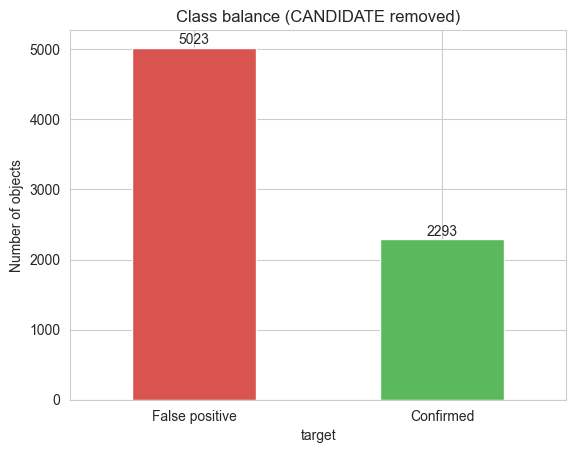

In [8]:
# Remplacer 0/1 par des noms lisibles et compter chaque classe
counts = data["target"].map({0: "False positive", 1: "Confirmed"}).value_counts()
# Barres rouge (faux positif) et verte (confirmé), étiquettes horizontales
ax = counts.plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0)
# Titre
ax.set_title("Class balance (CANDIDATE removed)")
# Nom de l'axe vertical
ax.set_ylabel("Number of objects")
# i = position de la barre, v = sa hauteur
for i, v in enumerate(counts):
    # Écrire le nombre exact au-dessus de chaque barre
    ax.text(i, v + 50, str(v), ha="center")
# Afficher le graphique
plt.show()

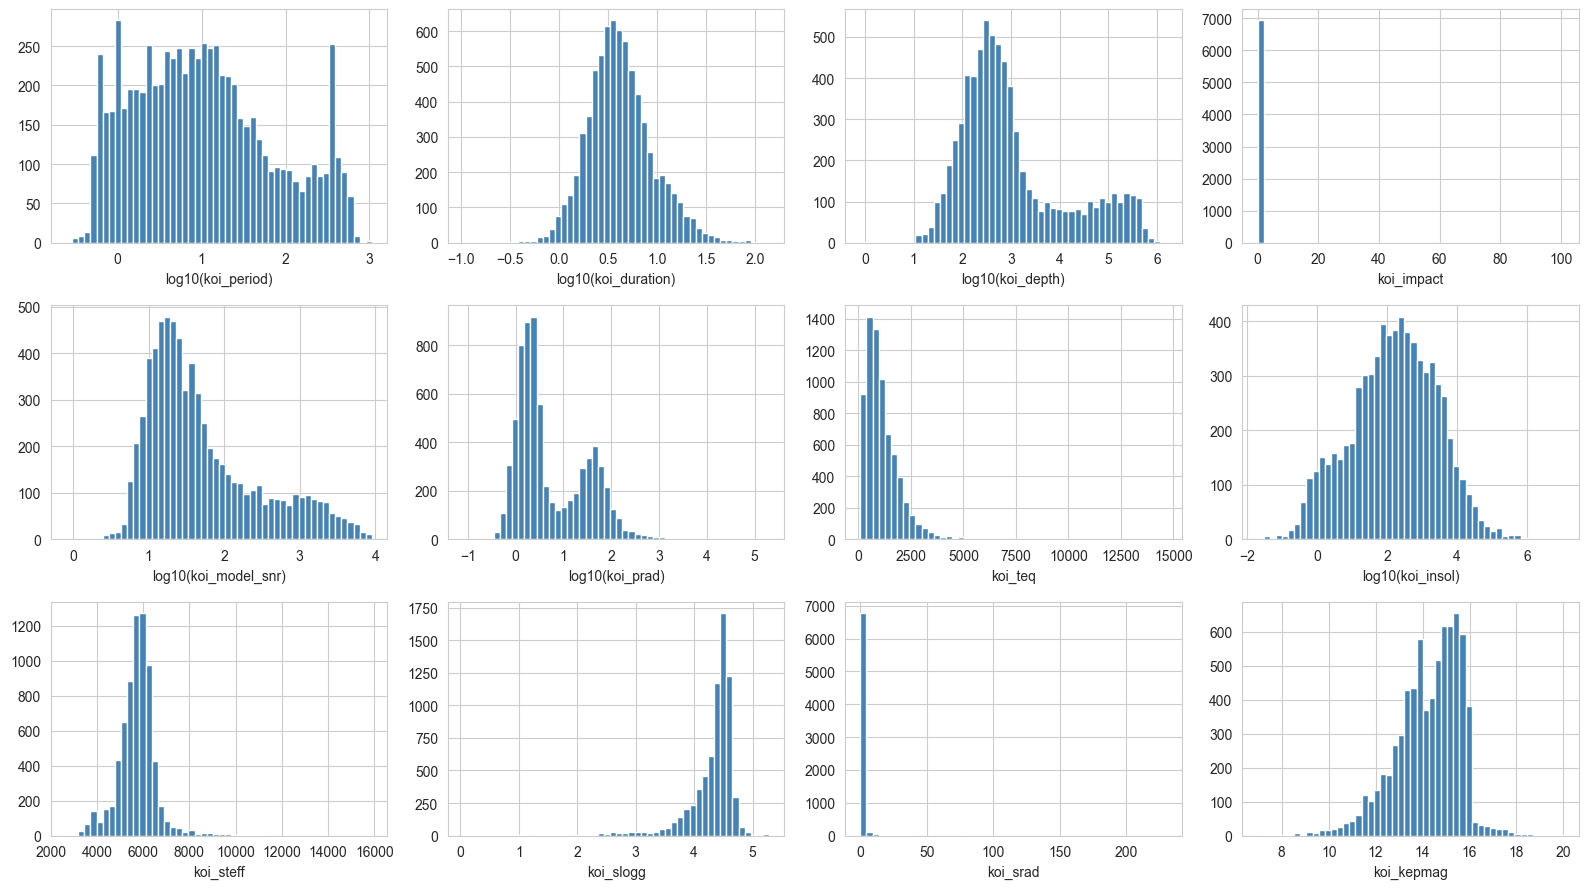

In [9]:
# Les 12 mesures physiques principales
main_cols = ["koi_period", "koi_duration", "koi_depth", "koi_impact",
             "koi_model_snr", "koi_prad", "koi_teq", "koi_insol",
             "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]
# Colonnes très étalées, affichées en échelle log
skewed = ["koi_period", "koi_depth", "koi_prad", "koi_model_snr", "koi_insol", "koi_duration"]

# Grille de 3 x 4 graphiques, 16 x 9 pouces
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
# ravel() met les 12 cases à plat ; zip associe une colonne à chaque case
for ax, col in zip(axes.ravel(), main_cols):
    # Valeurs de la colonne, sans les cases vides
    x = data[col].dropna()
    # Cas d'une colonne très étalée
    if col in skewed:
        # On garde les valeurs positives (log(0) n'existe pas) et on passe au log10
        x = np.log10(x[x > 0])
        # L'axe indique qu'il s'agit du log
        ax.set_xlabel(f"log10({col})")
    # Cas d'une colonne normale
    else:
        # Le nom de la colonne suffit
        ax.set_xlabel(col)
    # Histogramme à 50 intervalles
    ax.hist(x, bins=50, color="steelblue")
# Éviter que les graphiques se chevauchent
plt.tight_layout()
# Afficher la figure
plt.show()

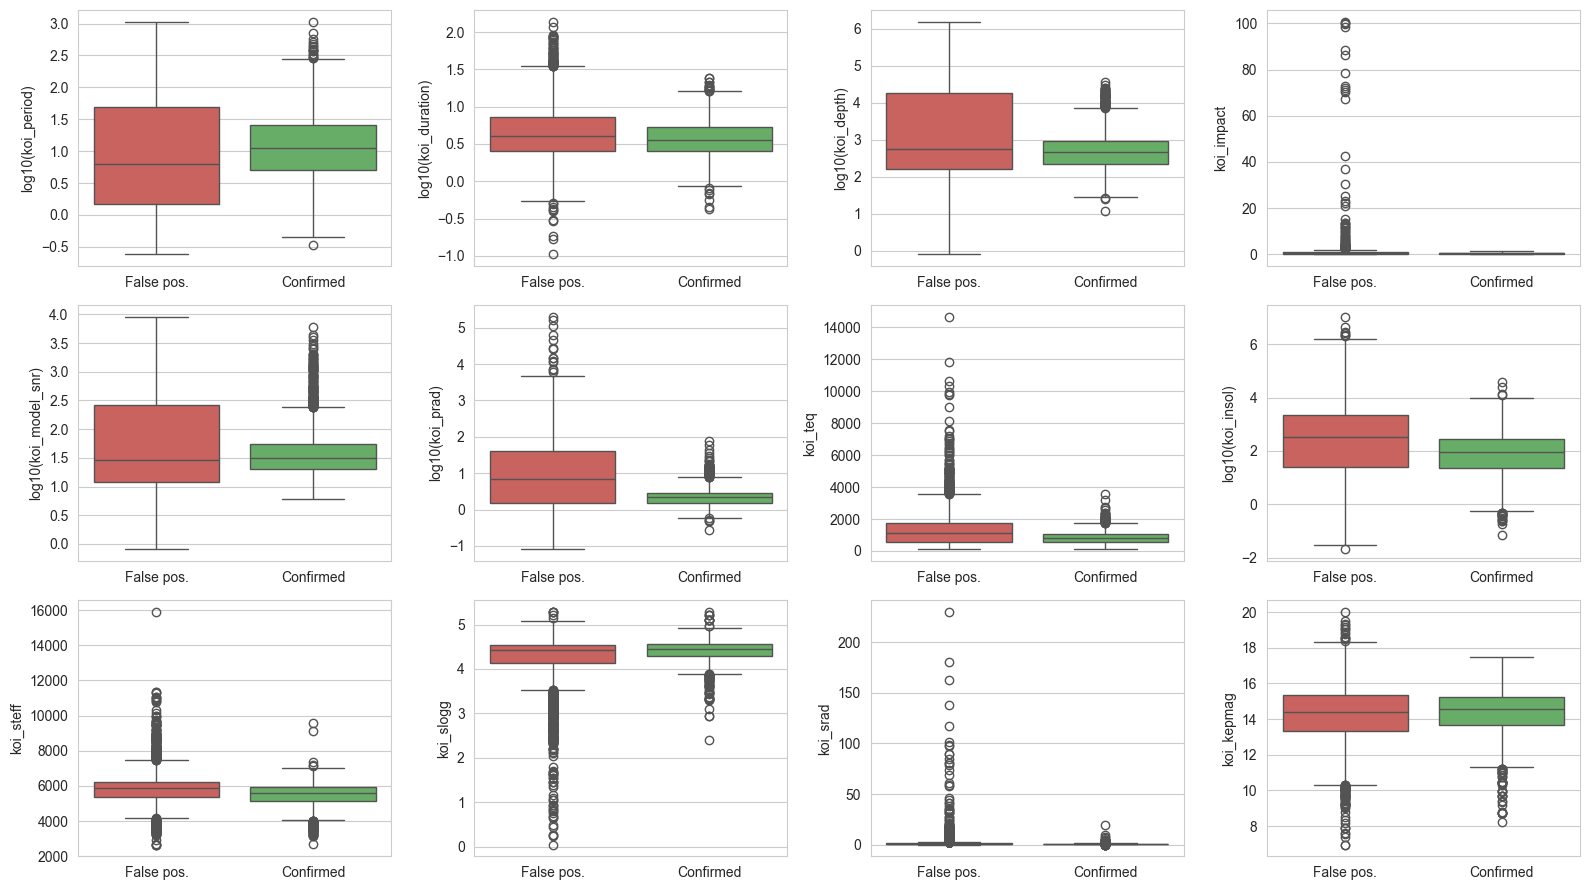

In [10]:
# Grille de 3 x 4 graphiques
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
# Une mesure par case
for ax, col in zip(axes.ravel(), main_cols):
    # La mesure et la cible, sans les lignes où la mesure manque
    plot_df = data[[col, "target"]].dropna()
    # Cas d'une colonne très étalée
    if col in skewed:
        # Le log exige des valeurs positives
        plot_df = plot_df[plot_df[col] > 0]
        # Remplacer les valeurs par leur log10
        plot_df[col] = np.log10(plot_df[col])
        # Nom de l'axe correspondant
        label = f"log10({col})"
    # Cas d'une colonne normale
    else:
        # On garde le nom de la colonne
        label = col
    # Boîte à moustaches par classe : rouge pour les faux positifs, vert pour les confirmées
    sns.boxplot(data=plot_df, x="target", y=col, ax=ax, palette=["#d9534f", "#5cb85c"], hue="target", legend=False)
    # Nom de l'axe vertical
    ax.set_ylabel(label)
    # Remplacer 0 et 1 par des noms lisibles
    ax.set_xticks([0, 1], ["False pos.", "Confirmed"])
    # Pas besoin de nom pour l'axe horizontal
    ax.set_xlabel("")
# Éviter les chevauchements
plt.tight_layout()
# Afficher la figure
plt.show()

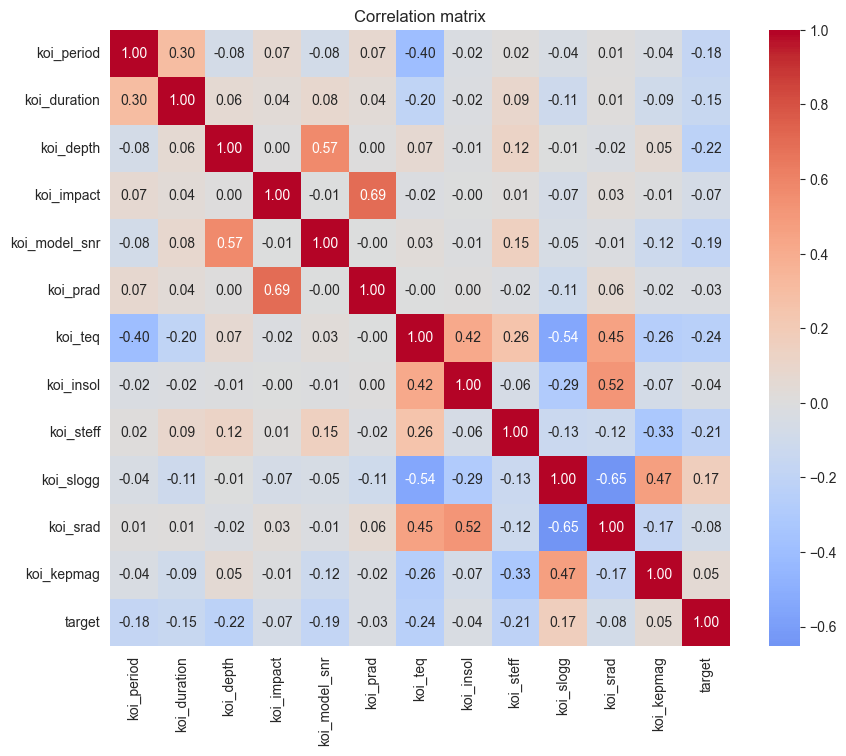

koi_teq         -0.24
koi_depth       -0.22
koi_steff       -0.21
koi_model_snr   -0.19
koi_period      -0.18
koi_slogg        0.17
koi_duration    -0.15
koi_srad        -0.08
koi_impact      -0.07
koi_kepmag       0.05
koi_insol       -0.04
koi_prad        -0.03
Name: target, dtype: float64


In [11]:
# Corrélations (de -1 à +1) entre les 12 mesures et la cible
corr = data[main_cols + ["target"]].corr()
# Figure de 10 x 8 pouces
plt.figure(figsize=(10, 8))
# Carte de chaleur avec les valeurs écrites à 2 décimales : bleu si négatif, rouge si positif
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
# Titre
plt.title("Correlation matrix")
# Afficher la figure
plt.show()

# Corrélation de chaque mesure avec la cible, de la plus forte à la plus faible (en valeur absolue)
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(2))


In [12]:
# Version du logiciel NASA (vides notés "missing") croisée avec la classe, totaux compris
print(pd.crosstab(data["koi_tce_delivname"].fillna("missing"), data["target"], margins=True))
# Saut de ligne
print()
# Numéro du signal sur son étoile croisé avec la classe, en proportion par ligne
print(pd.crosstab(data["koi_tce_plnt_num"], data["target"], normalize="index").round(2))

target                0     1   All
koi_tce_delivname                  
missing             271     8   279
q1_q16_tce          560     1   561
q1_q17_dr24_tce     216     3   219
q1_q17_dr25_tce    3976  2281  6257
All                5023  2293  7316

target               0     1
koi_tce_plnt_num            
1.0               0.73  0.27
2.0               0.36  0.64
3.0               0.31  0.69
4.0               0.24  0.76
5.0               0.42  0.58
6.0               0.67  0.33
7.0               0.86  0.14
8.0               1.00  0.00


In [13]:
# Les seuils sont fixés d'après l'astronomie et ne sont pas appris sur les données,
# donc on peut créer ces colonnes avant la séparation train/test sans fuite.
# Orbite : moins de 10 jours = courte, de 10 à 100 = moyenne, au-delà = longue
# (pd.cut découpe en intervalles, astype(object) convertit le résultat en texte)
data["type_orbite"] = pd.cut(data["koi_period"], bins=[0, 10, 100, np.inf],
                             labels=["short", "medium", "long"]).astype(object)

# Planète, selon le rayon en rayons terrestres :
# jusqu'à 1.25 taille Terre, puis super-Terre jusqu'à 2, type Neptune jusqu'à 6, type Jupiter au-delà
data["type_planete"] = pd.cut(data["koi_prad"], bins=[0, 1.25, 2, 6, np.inf],
                              labels=["earth_like", "super_earth", "neptune_like", "jupiter_like"]).astype(object)

# Étoile, selon sa température : froide sous 5200 K, proche du Soleil jusqu'à 6000 K, chaude au-delà
data["type_etoile"] = pd.cut(data["koi_steff"], bins=[0, 5200, 6000, np.inf],
                             labels=["cool", "sun_like", "hot"]).astype(object)

# Luminosité, selon la magnitude (un nombre plus grand veut dire une étoile plus faible) :
# brillante sous 13, moyenne jusqu'à 15, faible au-delà
data["luminosite"] = pd.cut(data["koi_kepmag"], bins=[0, 13, 15, np.inf],
                            labels=["bright", "medium", "faint"]).astype(object)

# Les 4 nouvelles colonnes catégorielles
new_cats = ["type_orbite", "type_planete", "type_etoile", "luminosite"]
# Pour chaque nouvelle colonne
for c in new_cats:
    # Effectif de chaque catégorie, cases vides comprises
    print(data[c].value_counts(dropna=False), "\n")

type_orbite
short     3871
medium    2316
long      1129
Name: count, dtype: int64 

type_planete
jupiter_like    2552
neptune_like    1884
super_earth     1386
earth_like      1194
NaN              300
Name: count, dtype: int64 

type_etoile
sun_like    3181
hot         2412
cool        1423
NaN          300
Name: count, dtype: int64 

luminosite
medium    3472
faint     2562
bright    1281
NaN          1
Name: count, dtype: int64 



In [14]:
# Les 13 colonnes numériques données aux modèles
main_num = ["koi_period", "koi_time0bk", "koi_impact", "koi_duration", "koi_depth",
            "koi_prad", "koi_teq", "koi_insol", "koi_model_snr",
            "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]

# Colonnes très étalées, passées au log avant la mise à l'échelle
log_cols = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_model_snr", "koi_insol"]

# y : ce qu'on veut prédire (0 = faux positif, 1 = confirmée)
y = data["target"]
# Entrées des modèles principaux : 13 colonnes numériques et 4 catégories
X_main     = data[main_num + new_cats]
# Les mêmes entrées plus les 2 colonnes proxy, pour l'expérience avec/sans
X_ablation = data[main_num + new_cats + proxy_cols]

# Tailles attendues : (7316, 17) et (7316, 19)
print(X_main.shape, X_ablation.shape)

(7316, 17) (7316, 19)


In [15]:
# Fonction de scikit-learn qui sépare entraînement et test
from sklearn.model_selection import train_test_split

# 20 % des lignes vont au test ; stratify=y garde la même part de planètes des deux côtés
# et random_state rend le tirage reproductible
idx_train, idx_test = train_test_split(
    data.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Lignes d'entraînement et de test pour la version principale
X_train, X_test = X_main.loc[idx_train], X_main.loc[idx_test]
# Les mêmes lignes pour la version ablation, pour comparer à armes égales
Xa_train, Xa_test = X_ablation.loc[idx_train], X_ablation.loc[idx_test]
# Les réponses correspondantes
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# 5852 lignes d'entraînement et 1464 de test
print(X_train.shape, X_test.shape)
# Part de planètes confirmées de chaque côté (environ 0.313 dans les deux cas)
print(y_train.mean().round(3), y_test.mean().round(3))

(5852, 17) (1464, 17)
0.313 0.314


In [16]:
# ColumnTransformer applique un traitement différent à chaque groupe de colonnes
from sklearn.compose import ColumnTransformer
# Pipeline enchaîne les étapes (prétraitement puis modèle) dans un seul objet
from sklearn.pipeline import Pipeline
# SimpleImputer remplit les valeurs manquantes
from sklearn.impute import SimpleImputer
# StandardScaler met à l'échelle (moyenne 0, écart-type 1), OneHotEncoder transforme le texte
# en colonnes 0/1, et FunctionTransformer applique une fonction au choix (ici le log)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Construit le prétraitement à partir des listes de colonnes
def make_preprocessor(num_cols, log_cols, cat_cols):
    # Colonnes numériques sans log
    plain_num = [c for c in num_cols if c not in log_cols]
    # Colonnes numériques avec log
    log_num   = [c for c in num_cols if c in log_cols]

    # Colonnes sans log : médiane pour les vides, puis mise à l'échelle
    plain_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                           ("scaler", StandardScaler())])
    # Colonnes étalées : médiane, log(1 + x), puis mise à l'échelle
    # (feature_names_out="one-to-one" conserve les noms des colonnes)
    log_pipe   = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("scaler", StandardScaler())])
    # Catégories : valeur la plus fréquente pour les vides, puis one-hot
    # (handle_unknown="ignore" évite une erreur si le test contient une catégorie jamais vue)
    cat_pipe   = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))])

    # Chaque traitement est appliqué à son groupe de colonnes
    return ColumnTransformer([("num", plain_pipe, plain_num),
                              ("lognum", log_pipe, log_num),
                              ("cat", cat_pipe, cat_cols)])

# Prétraitement de la version principale
prep_main = make_preprocessor(main_num, log_cols, new_cats)

# Version ablation : on ajoute les 2 colonnes proxy (une numérique, une catégorielle)
prep_ablation = make_preprocessor(main_num + ["koi_tce_plnt_num"], log_cols,
                                  new_cats + ["koi_tce_delivname"])

In [17]:
# Calculer médianes, moyennes et écarts-types sur l'entraînement seulement
prep_main.fit(X_train)
# Appliquer le prétraitement aux données d'entraînement
Z = prep_main.transform(X_train)
# Le one-hot ajoute des colonnes : on passe de 17 à 26
print("Shape after preprocessing:", Z.shape)
# Il ne doit plus rester de valeurs manquantes
print("Any missing values left:", np.isnan(Z).any())
# Noms des 10 premières colonnes produites
print(prep_main.get_feature_names_out()[:10])

Shape after preprocessing: (5852, 26)
Any missing values left: False
['num__koi_time0bk' 'num__koi_impact' 'num__koi_teq' 'num__koi_steff'
 'num__koi_slogg' 'num__koi_srad' 'num__koi_kepmag' 'lognum__koi_period'
 'lognum__koi_duration' 'lognum__koi_depth']


In [18]:
# Arbre de décision : une suite de questions oui/non sur les mesures
from sklearn.tree import DecisionTreeClassifier
# StratifiedKFold découpe en plis qui gardent la même part de chaque classe,
# cross_val_score calcule le score sur chaque pli
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Premier essai : prétraitement puis arbre de décision avec les réglages par défaut
pipe = Pipeline([("prep", prep_main),
                 ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])

# Validation croisée en 5 plis, mélangés de façon reproductible
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Le modèle est entraîné 5 fois, et chaque fois évalué (F1) sur le pli mis de côté
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
# F1 de chaque pli et moyenne
print("F1 per fold:", scores.round(3), "| mean:", scores.mean().round(3))

F1 per fold: [0.835 0.817 0.809 0.826 0.776] | mean: 0.813


In [19]:
# cross_validate calcule plusieurs métriques en une seule validation croisée
from sklearn.model_selection import cross_validate
# Random Forest : beaucoup d'arbres entraînés sur des échantillons différents, qui votent (bagging)
from sklearn.ensemble import RandomForestClassifier

# Les deux modèles comparés
models = {
    # Un seul arbre de décision
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    # 200 arbres ; n_jobs=-1 utilise tous les cœurs du processeur
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

# Les 4 métriques calculées sur chaque pli
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
# Mêmes 5 plis stratifiés que dans la cellule précédente
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Une ligne de résultats par modèle
rows = []
# Pour chaque modèle
for name, model in models.items():
    # Prétraitement puis modèle
    pipe = Pipeline([("prep", prep_main), ("model", model)])
    # Validation croisée avec les 4 métriques
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    # Moyenne de chaque métrique sur les 5 plis
    rows.append({"Model": name,
                 "Precision": res["test_precision"].mean(),
                 "Recall":    res["test_recall"].mean(),
                 "F1":        res["test_f1"].mean(),
                 "AUC-ROC":   res["test_roc_auc"].mean(),
                 # un écart-type faible veut dire que le modèle varie peu d'un pli à l'autre
                 "F1 std":    res["test_f1"].std()})
    # Indiquer que ce modèle est fini
    print(f"done: {name}")

# Tableau des résultats, trié par F1 et arrondi à 3 décimales
results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False).round(3)
# Afficher le tableau
results

done: Decision Tree
done: Random Forest


,Precision,Recall,F1,AUC-ROC,F1 std
Model,,,,,
Random Forest,0.875,0.870,0.872,0.973,0.006
Decision Tree,0.808,0.818,0.813,0.865,0.020


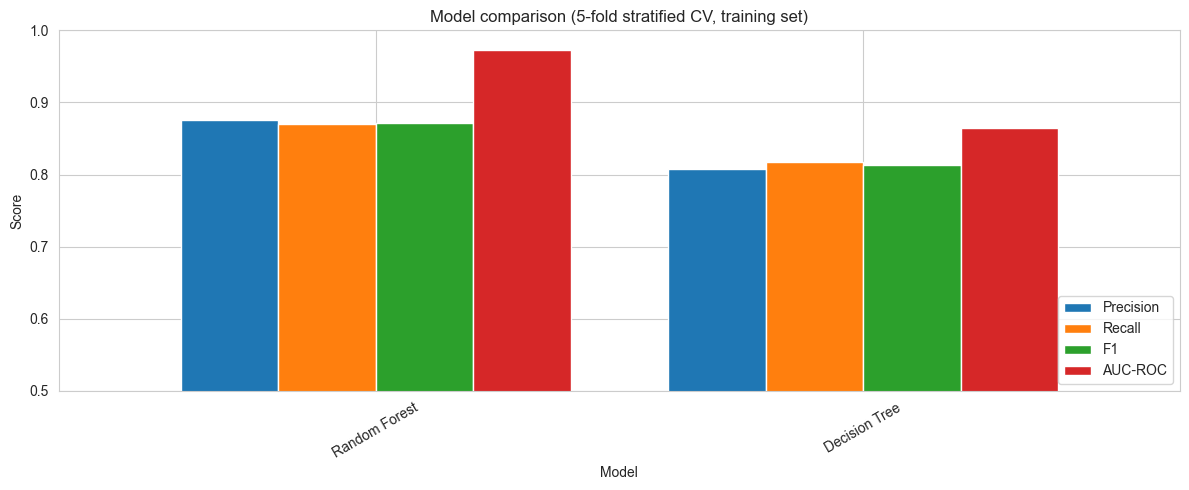

In [20]:
# Barres groupées : les 4 métriques de chaque modèle
ax = results[["Precision", "Recall", "F1", "AUC-ROC"]].plot(
    kind="bar", figsize=(12, 5), rot=30, width=0.8)
# Titre
ax.set_title("Model comparison (5-fold stratified CV, training set)")
# Nom de l'axe vertical
ax.set_ylabel("Score")
# L'axe commence à 0.5 pour que les écarts entre modèles restent visibles
ax.set_ylim(0.5, 1.0)
# Légende en bas à droite
ax.legend(loc="lower right")
# Éviter les chevauchements
plt.tight_layout()
# Afficher la figure
plt.show()

In [21]:
# RandomizedSearchCV essaie des réglages tirés au hasard et garde le meilleur
from sklearn.model_selection import RandomizedSearchCV
# randint tire un entier au hasard, uniform un nombre décimal
from scipy.stats import randint, uniform

# Pour chaque modèle : le modèle de base et les réglages (hyperparamètres) à essayer
search_spaces = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        # profondeur maximale de l'arbre (None = pas de limite)
        {"model__max_depth": [None, 4, 6, 8, 10, 15, 20],
         # nombre minimal d'objets dans une feuille, de 1 à 19
         "model__min_samples_leaf": randint(1, 20),
         # nombre minimal d'objets pour couper un nœud, de 2 à 19
         "model__min_samples_split": randint(2, 20),
         # mesure utilisée pour choisir la meilleure question
         "model__criterion": ["gini", "entropy"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        # entre 200 et 599 arbres
        {"model__n_estimators": randint(200, 600),
         # profondeur maximale des arbres (None = pas de limite)
         "model__max_depth": [None, 10, 20, 30],
         # nombre minimal d'objets dans une feuille, de 1 à 5
         "model__min_samples_leaf": randint(1, 6),
         # nombre de colonnes que chaque arbre examine à chaque question
         "model__max_features": ["sqrt", "log2", 0.5]}),
}

# Meilleur modèle trouvé et son F1 en validation croisée, pour chaque algorithme
best, cv_f1 = {}, {}
# Pour chaque algorithme à régler
for name, (model, space) in search_spaces.items():
    # Prétraitement puis modèle
    pipe = Pipeline([("prep", prep_main), ("model", model)])
    # 20 essais au hasard, chacun noté par le F1 en validation croisée à 5 plis
    rs = RandomizedSearchCV(pipe, space, n_iter=20, scoring="f1", cv=cv,
                            random_state=RANDOM_STATE, n_jobs=-1)
    # Lancer la recherche sur les données d'entraînement
    rs.fit(X_train, y_train)
    # Le meilleur modèle est réentraîné sur tout l'entraînement ; on le garde avec son score
    best[name], cv_f1[name] = rs.best_estimator_, rs.best_score_
    # Meilleur F1 obtenu
    print(f"{name}: best CV F1 = {rs.best_score_:.3f}")
    # Réglages correspondants
    print(rs.best_params_, "\n")

Decision Tree: best CV F1 = 0.846
{'model__criterion': 'gini', 'model__max_depth': 8, 'model__min_samples_leaf': 3, 'model__min_samples_split': 6} 

Random Forest: best CV F1 = 0.881
{'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 249} 



Decision Tree
                precision    recall  f1-score   support

False positive      0.934     0.927     0.931      1005
     Confirmed      0.843     0.856     0.850       459

      accuracy                          0.905      1464
     macro avg      0.889     0.892     0.890      1464
  weighted avg      0.905     0.905     0.905      1464

Random Forest
                precision    recall  f1-score   support

False positive      0.943     0.954     0.949      1005
     Confirmed      0.897     0.874     0.885       459

      accuracy                          0.929      1464
     macro avg      0.920     0.914     0.917      1464
  weighted avg      0.929     0.929     0.929      1464



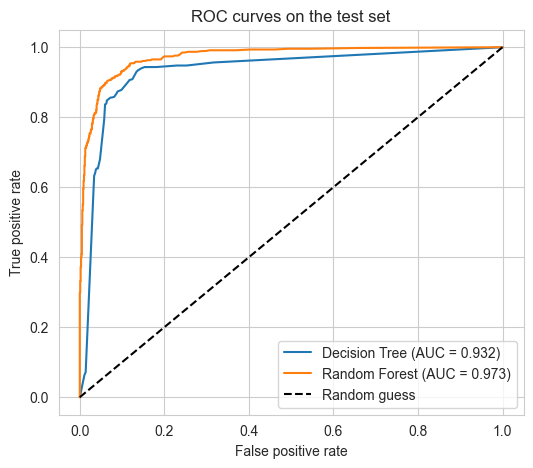

In [22]:
# Outils d'évaluation : rapport par classe, matrice de confusion, courbe ROC et son aire (AUC)
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

# Figure pour les courbes ROC
fig, ax = plt.subplots(figsize=(6, 5))
# Pour chacun des deux modèles réglés
for name, est in best.items():
    # Probabilité d'être une planète confirmée, pour chaque objet du test
    proba = est.predict_proba(X_test)[:, 1]
    # Points de la courbe ROC : taux de faux positifs et de vrais positifs pour chaque seuil
    fpr, tpr, _ = roc_curve(y_test, proba)
    # Tracer la courbe, avec l'AUC dans la légende
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
    # Nom du modèle
    print(name)
    # Précision, rappel et F1 de chaque classe sur le test
    print(classification_report(y_test, est.predict(X_test),
                                target_names=["False positive", "Confirmed"], digits=3))
# Diagonale en pointillés : ce que donnerait un tirage au hasard
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
# Noms des axes
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
# Titre et légende
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
# Afficher la figure
plt.show()

Final model: Random Forest


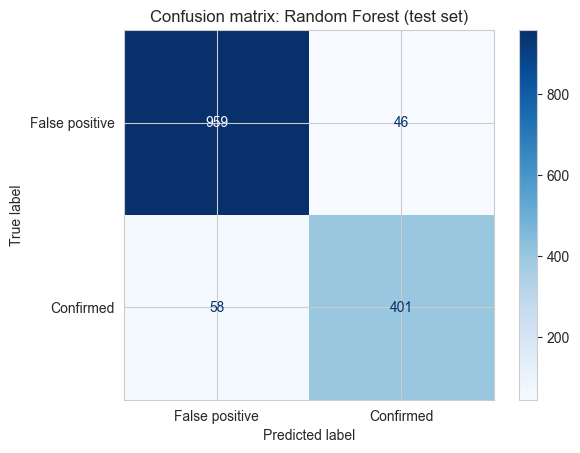

In [23]:
# Le modèle final est choisi sur le score de validation croisée, pas sur le test
final_name = max(cv_f1, key=cv_f1.get)
# Nom du modèle retenu
print("Final model:", final_name)
# Matrice de confusion sur le test : bonnes et mauvaises prédictions pour chaque classe
ConfusionMatrixDisplay.from_estimator(
    best[final_name], X_test, y_test,
    display_labels=["False positive", "Confirmed"], cmap="Blues")
# Titre
plt.title(f"Confusion matrix: {final_name} (test set)")
# Afficher la figure
plt.show()

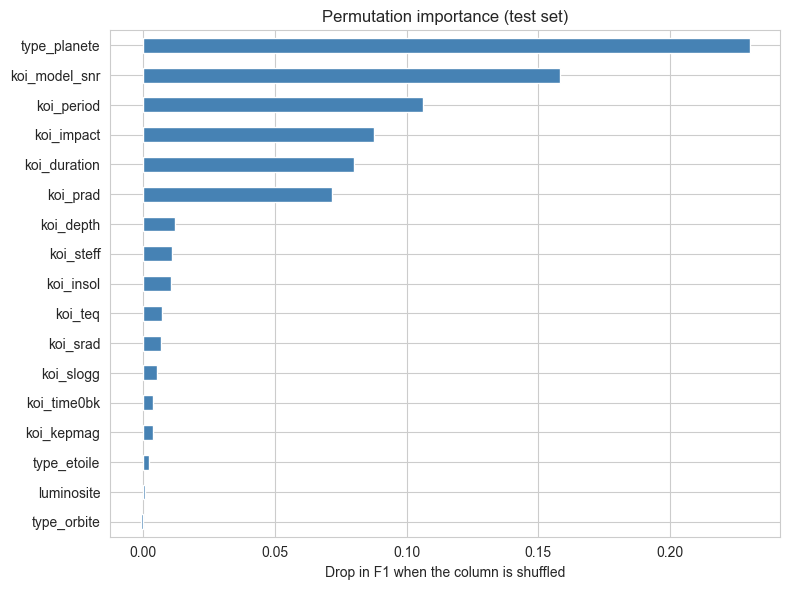

type_planete     0.2302
koi_model_snr    0.1582
koi_period       0.1063
koi_impact       0.0875
koi_duration     0.0798
koi_prad         0.0715
koi_depth        0.0120
koi_steff        0.0109
koi_insol        0.0104
koi_teq          0.0070
koi_srad         0.0066
koi_slogg        0.0051
koi_time0bk      0.0037
koi_kepmag       0.0035
type_etoile      0.0021
luminosite       0.0005
type_orbite     -0.0010
dtype: float64


In [24]:
# L'importance par permutation mesure à quel point le modèle dépend de chaque colonne
from sklearn.inspection import permutation_importance

# On mélange chaque colonne au hasard, 10 fois, et on mesure la baisse du F1 sur le test
r = permutation_importance(best[final_name], X_test, y_test, scoring="f1",
                           n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
# Baisse moyenne du F1 par colonne, de la plus petite à la plus grande
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()

# Barres horizontales
imp.plot(kind="barh", figsize=(8, 6), color="steelblue")
# Nom de l'axe horizontal
plt.xlabel("Drop in F1 when the column is shuffled")
# Titre
plt.title("Permutation importance (test set)")
# Éviter les chevauchements
plt.tight_layout()
# Afficher la figure
plt.show()
# Importances de la plus grande à la plus petite
print(imp.sort_values(ascending=False).round(4))

In [25]:
# clone fait une copie du modèle avec les mêmes réglages, mais pas encore entraînée
from sklearn.base import clone
# Score F1
from sklearn.metrics import f1_score

# Le modèle final réglé (celui choisi dans la cellule de la matrice de confusion)
final_model = best[final_name].named_steps["model"]

# Évalue le même modèle avec un prétraitement et des données donnés
def evaluate(prep, Xtr, Xte, label):
    # Pipeline avec une copie neuve du modèle final
    pipe = Pipeline([("prep", prep), ("model", clone(final_model))])
    # F1 moyen en validation croisée sur l'entraînement
    cv_f1 = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="f1").mean()
    # Entraînement sur tout l'ensemble d'entraînement
    pipe.fit(Xtr, y_train)
    # Probabilités sur le test, pour l'AUC
    proba = pipe.predict_proba(Xte)[:, 1]
    # Les 3 scores de cette version
    return {"Version": label, "CV F1": cv_f1,
            "Test F1": f1_score(y_test, pipe.predict(Xte)),
            "Test AUC": roc_auc_score(y_test, proba)}

# Comparer les deux versions dans un tableau
ablation = pd.DataFrame([
    # Version principale, sans les colonnes proxy
    evaluate(prep_main,     X_train,  X_test,  "Without proxy columns (main)"),
    # Version avec les 2 colonnes proxy
    evaluate(prep_ablation, Xa_train, Xa_test, "With koi_tce_delivname + koi_tce_plnt_num"),
]).set_index("Version").round(3)
# Afficher le tableau
ablation

,CV F1,Test F1,Test AUC
Version,,,
Without proxy columns (main),0.881,0.885,0.973
With koi_tce_delivname + koi_tce_plnt_num,0.882,0.885,0.975
